In [1]:

import os
import zipfile
import random
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()

zip_path = "train.zip"

print("File uploaded:", zip_path)


Saving train.zip to train.zip
File uploaded: train.zip


In [3]:
IMAGE_SIZE = (32, 32)
SAMPLES_PER_CLASS = 1000
RANDOM_STATE = 42

random.seed(RANDOM_STATE)

X = []
y = []

with zipfile.ZipFile(zip_path, "r") as z:
    image_names = [
        name for name in z.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
        and os.path.basename(name).lower().startswith(("cat.", "dog."))
    ]

    cat_names = [
        name for name in image_names
        if os.path.basename(name).lower().startswith("cat.")
    ]

    dog_names = [
        name for name in image_names
        if os.path.basename(name).lower().startswith("dog.")
    ]

    print("Cat images found:", len(cat_names))
    print("Dog images found:", len(dog_names))

    selected_names = (
        random.sample(cat_names, min(SAMPLES_PER_CLASS, len(cat_names)))
        + random.sample(dog_names, min(SAMPLES_PER_CLASS, len(dog_names)))
    )

    random.shuffle(selected_names)

    for name in selected_names:
        try:
            with z.open(name) as file:
                img = Image.open(file).convert("RGB")
                img = img.resize(IMAGE_SIZE)

                # Normalize pixel values to 0-1
                pixels = np.asarray(img, dtype=np.float32) / 255.0

                # Flatten image into a feature vector
                X.append(pixels.flatten())

                label = os.path.basename(name).lower()
                y.append(0 if label.startswith("cat.") else 1)

        except Exception as e:
            print("Skipped:", name, e)

X = np.array(X, dtype=np.float32)
y = np.array(y)

print("Feature array shape:", X.shape)
print("Label array shape:", y.shape)
print("Total images loaded:", len(y))

Cat images found: 12500
Dog images found: 12500
Feature array shape: (2000, 3072)
Label array shape: (2000,)
Total images loaded: 2000


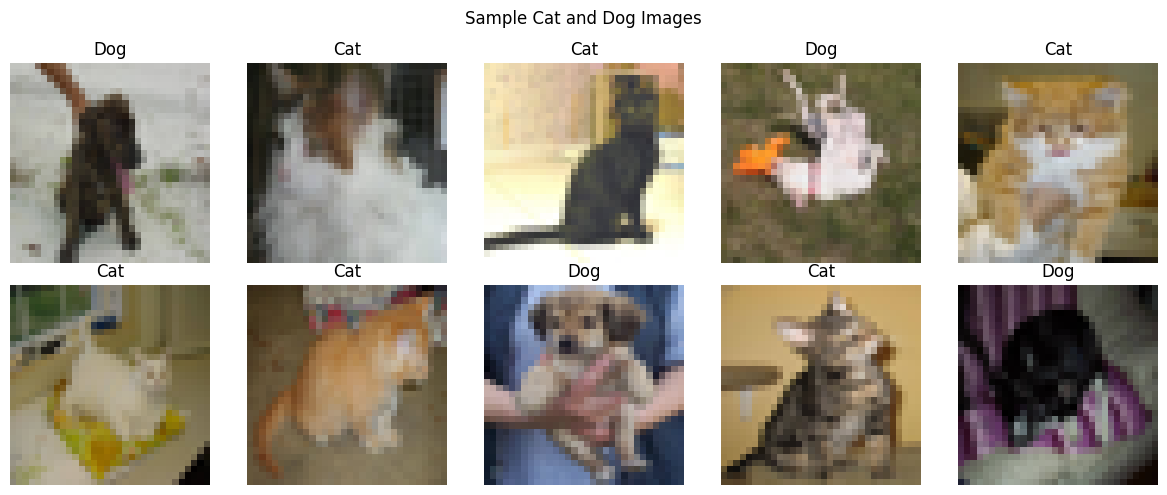

In [4]:
plt.figure(figsize=(12, 5))

for i in range(min(10, len(X))):
    plt.subplot(2, 5, i + 1)

    img = X[i].reshape(32, 32, 3)
    plt.imshow(img)

    label = "Dog" if y[i] == 1 else "Cat"
    plt.title(label)
    plt.axis("off")

plt.suptitle("Sample Cat and Dog Images")
plt.tight_layout()
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 1600
Testing images: 400


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    )
)

svm_model.fit(X_train, y_train)
print("SVM model training completed!")

SVM model training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [7]:
y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Cat", "Dog"],
        zero_division=0
    )
)

Test Accuracy: 51.50%

Classification Report:
              precision    recall  f1-score   support

         Cat       0.51      0.56      0.53       200
         Dog       0.52      0.47      0.49       200

    accuracy                           0.52       400
   macro avg       0.52      0.52      0.51       400
weighted avg       0.52      0.52      0.51       400



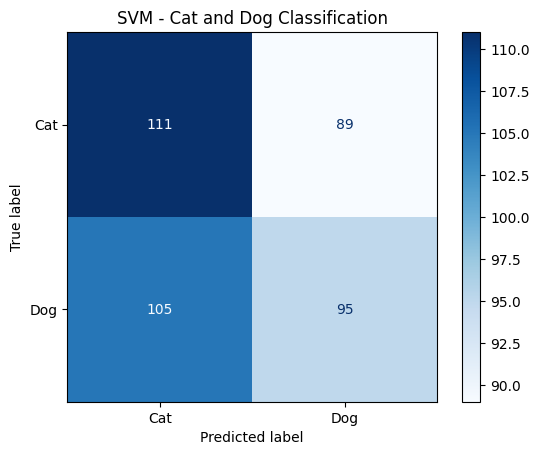

In [8]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

display.plot(cmap="Blues")
plt.title("SVM - Cat and Dog Classification")
plt.show()

Please upload a single image (JPG/PNG) to predict, or upload the train.zip to extract a sample image:


Saving train.zip to train (1).zip
'train (1).zip' is a zip file. Extracting a sample image for demonstration...
Selected sample: train/cat.0.jpg


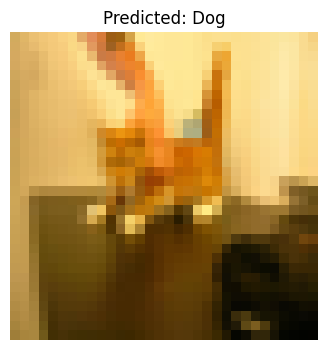

Prediction: Dog


In [11]:
import zipfile
from google.colab import files

print("Please upload a single image (JPG/PNG) to predict, or upload the train.zip to extract a sample image:")
uploaded_image = files.upload()

image_path = next(iter(uploaded_image))

# Check if the user accidentally uploaded a zip file
if image_path.lower().endswith('.zip'):
    print(f"'{image_path}' is a zip file. Extracting a sample image for demonstration...")
    with zipfile.ZipFile(image_path, 'r') as z:
        # Find the first image file inside the zip
        inside_images = [
            name for name in z.namelist()
            if name.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        if not inside_images:
            raise ValueError("No images found inside the uploaded zip archive.")

        # Select one sample image
        sample_name = inside_images[0]
        print(f"Selected sample: {sample_name}")
        with z.open(sample_name) as file:
            img = Image.open(file).convert("RGB")
else:
    # Normal image handling
    img = Image.open(image_path).convert("RGB")

# Apply the same preprocessing used during training
img = img.resize(IMAGE_SIZE)
img_array = np.asarray(img, dtype=np.float32) / 255.0
img_array = img_array.flatten().reshape(1, -1)

prediction = svm_model.predict(img_array)[0]

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.axis("off")
plt.title("Predicted: " + ("Dog" if prediction == 1 else "Cat"))
plt.show()

print("Prediction:", "Dog" if prediction == 1 else "Cat")

In [12]:
joblib.dump(svm_model, "cats_dogs_svm_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [13]:
files.download("cats_dogs_svm_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>